# DSA4213 Part II — public GloVe 6B-100d embeddings, frozen

## 1. Imports and Drive
For running in Colab

In [1]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
import sys, json, math, time, random, hashlib, platform, subprocess, shutil, copy, importlib.util
from pathlib import Path
from datetime import datetime, timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import DataLoader, TensorDataset
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(iterable, **kwargs): return iterable  # Epoch summaries still print.
from IPython.display import display

IN_COLAB = importlib.util.find_spec('google') is not None and importlib.util.find_spec('google.colab') is not None
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
print('Python:', sys.version.split()[0], '| PyTorch:', torch.__version__)

Mounted at /content/drive
Python: 3.13.15 | PyTorch: 2.11.0+cu130


## 2. Controls

In [2]:
PROJECT_ROOT=Path('/content/drive/MyDrive/DSA4213_Assignment1')
BASELINE_STUDY_ID='I_lstm_tuned_s42_v2'
VARIANT='glove_frozen'
RUN_ID='II_lstm_glove_frozen_s42_v1'
EMBEDDING_ID='partII_glove_frozen_100d_s42_v1'
TRAIN=True
MODE='auto'                  # 'auto', 'resume', 'new'
EVALUATE=True
RUN_GENERATION=True
RUN_BENCHMARK=True
BENCHMARK_GPU=True
RUN_CHECKS=True
CPU_THREADS=2
GLOVE_TEXT_PATH=None          # Optional: '/content/drive/MyDrive/.../glove.6B.100d.txt'
CBOW_CONFIG=dict(epochs=10,window=5,negative=5,sample=0.001,alpha=0.025,min_alpha=0.0001)
LOCAL_ROOT=Path('/content/dsa4213_partII_cache') if IN_COLAB else Path('./dsa4213_partII_cache')
LOCAL_ROOT.mkdir(parents=True,exist_ok=True)
assert MODE in {'auto','new','resume'}
assert '/' not in RUN_ID and '\\' not in RUN_ID
assert '/' not in EMBEDDING_ID and '\\' not in EMBEDDING_ID
DEVICE=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(CPU_THREADS)
torch.backends.cudnn.benchmark=False
torch.backends.cudnn.deterministic=True
if torch.cuda.is_available():
    torch.backends.cuda.matmul.allow_tf32=False; torch.backends.cudnn.allow_tf32=False
torch.use_deterministic_algorithms(True,warn_only=True)
print('Device:',DEVICE,'| GPU:',torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None)

Device: cuda | GPU: Tesla T4


In [3]:
def read_json(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))

def sha256(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b''): h.update(chunk)
    return h.hexdigest()

def object_hash(value):
    return hashlib.sha256(json.dumps(value, sort_keys=True).encode()).hexdigest()

def atomic_json(path, value):
    path = Path(path); tmp = path.with_name(path.name + '.tmp')
    tmp.write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False), encoding='utf-8')
    tmp.replace(path)

def atomic_torch(path, value):
    path = Path(path); tmp = path.with_name(path.name + '.tmp')
    torch.save(value, tmp); tmp.replace(path)

def seed_all(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)

def synchronize(device):
    if torch.device(device).type == 'cuda': torch.cuda.synchronize(device)

def safe_ppl(ce):
    return math.exp(ce) if ce < math.log(sys.float_info.max) else None


ORIGINAL_MODEL_SOURCE="import torch\nfrom torch import nn\n\nclass LSTMLanguageModel(nn.Module):\n    def __init__(self, config):\n        super().__init__()\n        self.config = dict(config)\n        self.embedding = nn.Embedding(config['vocab_size'], config['embedding_dim'], padding_idx=0)\n        self.input_dropout = nn.Dropout(config['dropout'])\n        self.lstm = nn.LSTM(config['embedding_dim'], config['hidden_size'],\n                            num_layers=config['num_layers'], batch_first=True,\n                            bidirectional=False, dropout=0.0)\n        self.output_dropout = nn.Dropout(config['dropout'])\n        self.output = nn.Linear(config['hidden_size'], config['vocab_size'])\n        mask = torch.zeros(config['vocab_size'], dtype=torch.bool)\n        mask[0] = True; mask[2] = True\n        self.register_buffer('input_only_mask', mask)\n\n    def token_states(self, x):\n        # No state argument: PyTorch initializes both h and c to zero each call.\n        states, _ = self.lstm(self.input_dropout(self.embedding(x)))\n        return states\n\n    def forward(self, x, return_states=False):\n        states = self.token_states(x)\n        logits = self.output(self.output_dropout(states))\n        logits = logits.masked_fill(self.input_only_mask, float('-inf'))\n        return (logits, states) if return_states else logits\n\n    def encode_mean(self, x):\n        # Use eval() and inference_mode() when extracting frozen representations.\n        states = self.token_states(x)\n        mask = (x != 0) & (x != 2) & (x != 3)\n        if torch.any(mask.sum(1) == 0): raise ValueError('No lexical token to pool.')\n        return (states * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True)\n"
MODEL_SOURCE="import torch\nfrom torch import nn\n\nclass LSTMLanguageModel(nn.Module):\n    def __init__(self, config):\n        super().__init__()\n        self.config = dict(config)\n        self.embedding = nn.Embedding(config['vocab_size'], config['embedding_dim'], padding_idx=0)\n        self.embedding.weight.requires_grad_(config.get('embedding_mode', 'random_trainable') == 'random_trainable')\n        self.input_dropout = nn.Dropout(config['dropout'])\n        self.lstm = nn.LSTM(config['embedding_dim'], config['hidden_size'],\n                            num_layers=config['num_layers'], batch_first=True,\n                            bidirectional=False, dropout=0.0)\n        self.output_dropout = nn.Dropout(config['dropout'])\n        self.output = nn.Linear(config['hidden_size'], config['vocab_size'])\n        mask = torch.zeros(config['vocab_size'], dtype=torch.bool)\n        mask[0] = True; mask[2] = True\n        self.register_buffer('input_only_mask', mask)\n\n    def token_states(self, x):\n        # No state argument: PyTorch initializes both h and c to zero each call.\n        states, _ = self.lstm(self.input_dropout(self.embedding(x)))\n        return states\n\n    def forward(self, x, return_states=False):\n        states = self.token_states(x)\n        logits = self.output(self.output_dropout(states))\n        logits = logits.masked_fill(self.input_only_mask, float('-inf'))\n        return (logits, states) if return_states else logits\n\n    def encode_mean(self, x):\n        # Use eval() and inference_mode() when extracting frozen representations.\n        states = self.token_states(x)\n        mask = (x != 0) & (x != 2) & (x != 3)\n        if torch.any(mask.sum(1) == 0): raise ValueError('No lexical token to pool.')\n        return (states * mask.unsqueeze(-1)).sum(1) / mask.sum(1, keepdim=True)\n"

## 3. Load the validation-selected Part I configuration

In [4]:
BASE_STUDY = PROJECT_ROOT/'runs'/BASELINE_STUDY_ID
selection_path = BASE_STUDY/'selection.json'
if not selection_path.exists():
    raise FileNotFoundError(f'Complete the tuned Part I notebook first. Missing: {selection_path}')
selection = read_json(selection_path)
BASE_DIR = (BASE_STUDY/selection['relative_dir']).resolve()
assert BASE_STUDY.resolve() in BASE_DIR.parents, 'Invalid selected trial path.'
required_baseline = ['config.json','best.pt','initial_weights.pt','training_summary.json',
                     'history.csv','lstm_model.py','environment.json']
for name in required_baseline:
    if not (BASE_DIR/name).exists(): raise FileNotFoundError(f'Missing baseline artifact: {BASE_DIR/name}')
BASE_CFG = read_json(BASE_DIR/'config.json')
assert BASE_CFG == selection['selected_config'], 'Selection/config mismatch.'
base_summary = read_json(BASE_DIR/'training_summary.json')
assert base_summary['complete'], 'The selected baseline has not completed training.'
base_package = torch.load(BASE_DIR/'best.pt', map_location='cpu', weights_only=True)
assert base_package['config'] == BASE_CFG
assert base_package['model_source_sha256'] == sha256(BASE_DIR/'lstm_model.py')
assert (BASE_DIR/'lstm_model.py').read_text() == ORIGINAL_MODEL_SOURCE, 'Unexpected baseline architecture; inspect before proceeding.'
assert BASE_CFG['embedding_mode'] == 'random_trainable' and BASE_CFG['embedding_dim'] == 100
assert BASE_CFG['precision'] == 'float32'
base_initial = torch.load(BASE_DIR/'initial_weights.pt',map_location='cpu',weights_only=True)
baseline_identity = dict(study_id=BASELINE_STUDY_ID, selected_trial=selection['selected_trial'],
    checkpoint_sha256=sha256(BASE_DIR/'best.pt'), initial_weights_sha256=sha256(BASE_DIR/'initial_weights.pt'),
    config_sha256=sha256(BASE_DIR/'config.json'))
REQUESTED = BASE_CFG
print('Locked baseline:', BASE_DIR)
display(pd.DataFrame({k:[BASE_CFG[k]] for k in ['embedding_dim','hidden_size','num_layers','dropout',
    'learning_rate','batch_size','epochs','early_stopping_patience','scheduler_patience']}))
print('Each variant chooses its own best epoch under the same stopping policy.')

Locked baseline: /content/drive/MyDrive/DSA4213_Assignment1/runs/I_lstm_tuned_s42_v2/trials/trial_07_hidden_size


,embedding_dim,hidden_size,num_layers,dropout,learning_rate,batch_size,epochs,early_stopping_patience,scheduler_patience
0,100,256,1,0.2,0.001,32,50,7,2


Each variant chooses its own best epoch under the same stopping policy.


## 4. Verify the original data contract

In [5]:
common = read_json(PROJECT_ROOT / 'configs/common.json')
DATA_DIR = PROJECT_ROOT / common['processed_dir_relative']
complete = read_json(DATA_DIR / 'COMPLETE.json')
assert complete['data_version'] == common['data_version']
required = ['config.json', 'vocab.json', 'preprocessing.py', 'generation_prompts.json',
            'data_summary.csv', 'environment.json', 'source.json']
required += [f'{s}_{suffix}' for s in ['train','validation','test']
             for suffix in ['blocks.npz','manifest.csv']]
for name in required:
    assert name in complete['sha256'], f'Missing checksum: {name}'
    assert sha256(DATA_DIR / name) == complete['sha256'][name], f'Changed input: {name}'
assert read_json(DATA_DIR / 'config.json') == common, 'common.json no longer matches saved data.'
assert common['special_ids'] == {'PAD': 0, 'UNK': 1, 'BOS': 2, 'EOS': 3}
assert common['reset_state_each_block'] is True
PAD, UNK, BOS, EOS = 0, 1, 2, 3
vocab = read_json(DATA_DIR / 'vocab.json')
id_to_token, token_to_id = vocab['id_to_token'], vocab['token_to_id']
V = len(id_to_token); T = int(common['block_length'])
assert V == common['vocab_size'] and V > 4
assert token_to_id == {t:i for i,t in enumerate(id_to_token)}
assert common['predicted_ids'] == [i for i in range(V) if i not in (PAD, BOS)]
assert REQUESTED['embedding_dim'] == common['embedding_dimension']
prompts = read_json(DATA_DIR / 'generation_prompts.json')
assert prompts and all(p['ids'] for p in prompts)
for p in prompts:
    assert all(0 <= i < V and i not in (PAD,BOS,EOS) for i in p['ids'])
    if UNK in p['ids']: print('Prompt contains UNK:', p['text'])

arrays, manifests, data_checks = {}, {}, []
CACHE = LOCAL_ROOT / common['data_version']; CACHE.mkdir(exist_ok=True)
for split in ['train', 'validation', 'test']:
    name = f'{split}_blocks.npz'; local = CACHE / name
    if not local.exists() or sha256(local) != complete['sha256'][name]:
        shutil.copy2(DATA_DIR / name, local)
    with np.load(local, allow_pickle=False) as z:
        x, y = z['x'].astype(np.int64), z['y'].astype(np.int64)
    m = pd.read_csv(DATA_DIR / f'{split}_manifest.csv')
    assert x.shape == y.shape == (len(m), T) and len(m) > 0
    assert np.array_equal(m.block_id.to_numpy(), np.arange(len(m)))
    lengths = m.valid_length.to_numpy()
    assert np.all((lengths > 0) & (lengths <= T))
    valid = np.arange(T)[None,:] < lengths[:,None]
    assert np.array_equal(y != PAD, valid) and np.array_equal(x != PAD, valid)
    assert x.min() >= 0 and y.min() >= 0 and max(x.max(),y.max()) < V
    assert not np.any(y == BOS)
    shifted = np.arange(T-1)[None,:] < (lengths-1)[:,None]
    assert np.array_equal(x[:,1:][shifted], y[:,:-1][shifted])
    for i, row in enumerate(m.itertuples(index=False)):
        if row.offset == 0:
            assert x[i,0] == BOS
        else:
            assert i > 0 and m.iloc[i-1].row_id == row.row_id
            assert row.offset == m.iloc[i-1].offset + T
            assert x[i,0] == y[i-1,-1]
        is_end = i == len(m)-1 or m.iloc[i+1].row_id != row.row_id
        assert (y[i, row.valid_length-1] == EOS) == is_end
    arrays[split] = (x,y); manifests[split] = m
    data_checks.append(dict(split=split, blocks=len(x), scored_tokens=int(valid.sum()),
        target_sha256=hashlib.sha256(y[valid].astype('<i8').tobytes()).hexdigest(),
        unknown_target_rate=float((y[valid] == UNK).mean())))
display(pd.DataFrame(data_checks))
display(pd.read_csv(DATA_DIR / 'data_summary.csv'))
print('Saved prompts:', [p['text'] for p in prompts])

,split,blocks,scored_tokens,target_sha256,unknown_target_rate
0,train,46109,2136678,9929fab2f9c24e21ddfdbde443912a3b008de91942ba29...,0.075215
1,validation,4845,223705,8e251aab5a325eecd02f3c9a3a5bc83af1894281b81877...,0.091415
2,test,5652,252697,223687d4aa0f88b2e0fe543e12504c63df4774dbc86df5...,0.099681


,split,raw_rows,retained_rows,removed_rows,lexical_tokens,unknown_tokens,unknown_pct,median_row_tokens,p95_row_tokens,max_row_tokens,vocab_size
0,train,36718,21441,15277,2115237,160711,7.597777,90.0,252.0,746,10000
1,validation,3760,2297,1463,221408,20450,9.236342,86.0,245.0,437,10000
2,test,4358,2792,1566,249905,25189,10.079430,76.0,245.0,497,10000


Saved prompts: ['the history of', 'the city is', 'during the first', 'the team won']


## 5. Prepare or load embeddings

In [6]:
for key, value in [('vocab_sha256',sha256(DATA_DIR/'vocab.json')),
                   ('data_manifest_sha256',sha256(DATA_DIR/'COMPLETE.json')),
                   ('prompts_sha256',sha256(DATA_DIR/'generation_prompts.json'))]:
    assert BASE_CFG[key] == value, f'Baseline/data mismatch: {key}'
assert BASE_CFG['vocab_size'] == V and BASE_CFG['block_length'] == T
assert base_initial['embedding.weight'].shape == (V,100)

EMBED_DIR = PROJECT_ROOT/'embeddings'/EMBEDDING_ID
embedding_matrix = base_initial['embedding.weight'].clone().float()
coverage_mask = np.zeros(V,dtype=bool)
embedding_record = dict(method='random_trainable', embedding_training_seconds=0.0,
    setup_seconds=0.0, note='Original random initialization; learned jointly in Part I.')

if VARIANT != 'random_trainable':
    token_path = DATA_DIR/'train_tokens.jsonl'
    assert 'train_tokens.jsonl' in complete['sha256']
    assert sha256(token_path) == complete['sha256']['train_tokens.jsonl']
    embed_config = dict(variant=VARIANT, dimension=100, vocab_sha256=BASE_CFG['vocab_sha256'],
        train_tokens_sha256=sha256(token_path), baseline_initial_sha256=baseline_identity['initial_weights_sha256'],
        fallback='original baseline random vector; PAD=0; entire table frozen',
        cbow=CBOW_CONFIG if VARIANT=='cbow_frozen' else None,
        public_source='glove-wiki-gigaword-100 / Stanford GloVe 6B 100d' if VARIANT=='glove_frozen' else None,
        source_mode=('manual_text' if GLOVE_TEXT_PATH else 'gensim_downloader') if VARIANT=='glove_frozen' else None)
    ready = EMBED_DIR/'COMPLETE.json'
    if ready.exists():
        saved = read_json(ready)
        assert saved['config'] == embed_config, 'Embedding settings changed; choose a new EMBEDDING_ID and RUN_ID.'
        for name, digest in saved['files'].items(): assert sha256(EMBED_DIR/name)==digest, f'Changed embedding file: {name}'
        embedding_matrix = torch.from_numpy(np.load(EMBED_DIR/'matrix.npy',allow_pickle=False))
        coverage_mask = np.load(EMBED_DIR/'coverage_mask.npy',allow_pickle=False)
        embedding_record = read_json(EMBED_DIR/'embedding_record.json')
        print('Loaded saved embedding matrix; no embedding training/download.')
    else:
        if not TRAIN: raise FileNotFoundError('No completed embedding cache. Run once with TRAIN=True.')
        EMBED_DIR.mkdir(parents=True,exist_ok=True)
        if (EMBED_DIR/'config.json').exists():
            assert read_json(EMBED_DIR/'config.json') == embed_config, 'Partial embedding configuration mismatch.'
        atomic_json(EMBED_DIR/'config.json',embed_config)
        if importlib.util.find_spec('gensim') is None:
            subprocess.check_call([sys.executable,'-m','pip','install','gensim>=4.4,<5'])
        try:
            import gensim
        except ImportError as e:
            raise ImportError('Install a compatible gensim in Colab, restart the runtime, then Run all. Do not replace PyTorch.') from e
        setup_start=time.perf_counter()
        if VARIANT=='cbow_frozen':
            from gensim.models import Word2Vec
            from gensim.models.callbacks import CallbackAny2Vec
            def stable_hash(word):
                return int.from_bytes(hashlib.sha256(str(word).encode()).digest()[:4],'little')
            class TrainingRows:
                def __iter__(self):
                    with token_path.open(encoding='utf-8') as f:
                        for line in f:
                            row=json.loads(line)
                            # Preserve row boundaries and positions; out-of-vocabulary words become UNK.
                            words=[id_to_token[token_to_id.get(t,UNK)] for t in row['tokens']]
                            if words: yield words
            class EmbeddingLog(CallbackAny2Vec):
                def __init__(self): self.rows=[]; self.previous=0.0
                def on_epoch_begin(self, model): self.start=time.perf_counter()
                def on_epoch_end(self, model):
                    current=float(model.get_latest_training_loss())
                    row=dict(epoch=len(self.rows)+1,negative_sampling_loss=current-self.previous,
                             seconds=time.perf_counter()-self.start)
                    self.rows.append(row); self.previous=current
                    print(f"CBOW epoch {row['epoch']}/{CBOW_CONFIG['epochs']} | loss sum {row['negative_sampling_loss']:.1f}")
            cbow_start=time.perf_counter()
            w2v=Word2Vec(vector_size=100,sg=0,hs=0,negative=CBOW_CONFIG['negative'],
                window=CBOW_CONFIG['window'],min_count=1,workers=1,seed=42,
                sample=CBOW_CONFIG['sample'],alpha=CBOW_CONFIG['alpha'],min_alpha=CBOW_CONFIG['min_alpha'],
                cbow_mean=1,sorted_vocab=1,shrink_windows=True,hashfxn=stable_hash)
            sentences=TrainingRows(); w2v.build_vocab(sentences)
            assert w2v.corpus_count > 0 and len(w2v.wv)>1
            callback=EmbeddingLog()
            w2v.train(sentences,total_examples=w2v.corpus_count,epochs=CBOW_CONFIG['epochs'],
                      compute_loss=True,callbacks=[callback])
            embedding_training_seconds=time.perf_counter()-cbow_start
            vectors=w2v.wv
            pd.DataFrame(callback.rows).to_csv(EMBED_DIR/'cbow_history.csv',index=False)
            # Native KeyedVectors retain the trained vectors without a custom hash-function pickle.
            vectors.save(str(EMBED_DIR/'cbow_vectors.kv'),separately=[])
            source_details=dict(training_rows=w2v.corpus_count,training_tokens=w2v.corpus_total_words,
                algorithm='CBOW with negative sampling',workers=1,seed=42,
                training_loss_note='Unnormalized sampled objective; not LM CE/PPL and not an early-stopping criterion.')
        else:
            embedding_training_seconds=0.0
            if GLOVE_TEXT_PATH:
                path=Path(GLOVE_TEXT_PATH)
                if not path.is_file(): raise FileNotFoundError(path)
                # Stream only needed rows; avoid loading the full public vocabulary into RAM.
                vectors={}
                with path.open(encoding='utf-8') as f:
                    for line in f:
                        fields=line.rstrip().split()
                        if fields and fields[0] in token_to_id and token_to_id[fields[0]]>=4:
                            if len(fields)!=101: raise ValueError('Expected glove.6B.100d.txt with 100 numbers per word.')
                            vec=np.asarray(fields[1:],dtype=np.float32)
                            if not np.isfinite(vec).all(): raise ValueError('Nonfinite public vector.')
                            vectors[fields[0]]=vec
                source_details=dict(source='Stanford GloVe 6B 100d',filename=path.name,sha256=sha256(path))
            else:
                import gensim.downloader as api
                print('First run downloads glove-wiki-gigaword-100 (the same GloVe 6B 100d vectors).')
                vectors=api.load('glove-wiki-gigaword-100')
                assert vectors.vector_size==100
                source_details=dict(source='Stanford GloVe 6B 100d via gensim-data',
                    downloader_name='glove-wiki-gigaword-100',upstream_metadata=api.info('glove-wiki-gigaword-100'))
        for i,word in enumerate(id_to_token):
            eligible = i>=4 or (VARIANT=='cbow_frozen' and i==UNK)
            if eligible and word in vectors:
                embedding_matrix[i]=torch.from_numpy(np.asarray(vectors[word],dtype=np.float32).copy())
                coverage_mask[i]=True
        embedding_matrix[PAD].zero_()
        assert embedding_matrix.shape==(V,100) and torch.isfinite(embedding_matrix).all()
        assert coverage_mask[4:].any(), 'No vocabulary matches; inspect public file/tokenization.'
        embedding_record=dict(method=VARIANT,embedding_training_seconds=embedding_training_seconds,
            setup_seconds=time.perf_counter()-setup_start,source=source_details,
            gensim_version=gensim.__version__,created_utc=datetime.now(timezone.utc).isoformat(),
            hardware=dict(cpu=platform.processor() or platform.machine(),logical_cpus=os.cpu_count()),
            special_tokens='PAD zero; BOS/EOS original random; CBOW UNK trained when observed, otherwise original random; public UNK original random.',
            fallback='Keep original baseline random vectors for missing tokens; freeze all rows.',
            normalization='No vector normalization or rescaling.')
        np.save(EMBED_DIR/'matrix.npy',embedding_matrix.numpy(),allow_pickle=False)
        np.save(EMBED_DIR/'coverage_mask.npy',coverage_mask,allow_pickle=False)
        atomic_json(EMBED_DIR/'embedding_record.json',embedding_record)
        names=['matrix.npy','coverage_mask.npy','embedding_record.json','config.json']
        if VARIANT=='cbow_frozen': names += ['cbow_history.csv','cbow_vectors.kv']
        atomic_json(ready,dict(config=embed_config,files={n:sha256(EMBED_DIR/n) for n in names}))
        del vectors
        if VARIANT=='cbow_frozen': del w2v
    assert embedding_matrix.shape==(V,100) and embedding_matrix.dtype==torch.float32
    assert torch.isfinite(embedding_matrix).all() and torch.count_nonzero(embedding_matrix[PAD])==0
    assert coverage_mask.shape==(V,) and coverage_mask.dtype==np.bool_
    coverage=[]
    for split,(_,y) in arrays.items():
        lexical=y[(y!=PAD)&(y!=BOS)&(y!=EOS)]
        known=lexical[lexical>=4]
        coverage.append(dict(split=split,ordinary_vocab_types=V-4,
            covered_vocab_types=int(coverage_mask[4:].sum()),type_coverage=float(coverage_mask[4:].mean()),
            lexical_target_tokens=len(lexical),known_lexical_tokens=len(known),
            token_coverage_including_UNK=float(coverage_mask[lexical].mean()),
            token_coverage_known_only=float(coverage_mask[known].mean()) if len(known) else None,
            unknown_rate=float((lexical==UNK).mean())))
    coverage_df=pd.DataFrame(coverage)
    display(coverage_df.round(4))
    coverage_df.to_csv(EMBED_DIR/'coverage.csv',index=False)
    pd.DataFrame({'id':np.arange(V),'token':id_to_token,'source_vector_available':coverage_mask}).to_csv(
        EMBED_DIR/'vocabulary_coverage.csv',index=False)
    print('Embedding training seconds:',embedding_record['embedding_training_seconds'])
    if VARIANT=='cbow_frozen':
        ch=pd.read_csv(EMBED_DIR/'cbow_history.csv')
        fig,ax=plt.subplots(figsize=(7,3))
        ax.plot(ch.epoch,ch.negative_sampling_loss,marker='o')
        ax.set(xlabel='CBOW epoch',ylabel='Sampled loss sum',title='CBOW training objective (not language-model CE)')
        ax.grid(alpha=.2); fig.tight_layout(); fig.savefig(EMBED_DIR/'cbow_loss.png'); plt.show()

First run downloads glove-wiki-gigaword-100 (the same GloVe 6B 100d vectors).
[==================================================] 100.0% 128.1/128.1MB downloaded


,split,ordinary_vocab_types,covered_vocab_types,type_coverage,lexical_target_tokens,known_lexical_tokens,token_coverage_including_UNK,token_coverage_known_only,unknown_rate
0,train,9996,9919,0.9923,2115237,1954526,0.9229,0.9988,0.0760
1,validation,9996,9919,0.9923,221408,200958,0.9074,0.9997,0.0924
2,test,9996,9919,0.9923,249905,224716,0.8991,0.9998,0.1008


Embedding training seconds: 0.0


## 6. Run identity, model, hardware and initialization

In [7]:
def environment_snapshot():
    cpu = platform.processor() or platform.machine()
    if Path('/proc/cpuinfo').exists():
        cpu = next((s.split(':',1)[1].strip() for s in Path('/proc/cpuinfo').read_text().splitlines()
                    if s.startswith('model name')), cpu)
    ram = None
    if Path('/proc/meminfo').exists():
        ram = int(Path('/proc/meminfo').read_text().splitlines()[0].split()[1]) / 1024**2
    versions = {}
    for p in ['torch','numpy','pandas','matplotlib','tqdm','gensim','scikit-learn','datasets','huggingface_hub']:
        try: versions[p] = metadata.version(p)
        except metadata.PackageNotFoundError: versions[p] = None
    return dict(utc=datetime.now(timezone.utc).isoformat(), python=sys.version, platform=platform.platform(),
        cpu=cpu, cpu_threads=torch.get_num_threads(), logical_cpus=os.cpu_count(), ram_gib=ram,
        cuda_available=torch.cuda.is_available(), cuda_runtime=torch.version.cuda,
        cudnn=torch.backends.cudnn.version(), device=str(DEVICE), precision='float32',
        gpu_name=torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
        gpu_memory_gib=torch.cuda.get_device_properties(0).total_memory/1024**3 if torch.cuda.is_available() else None,
        packages=versions, deterministic_algorithms='warn_only', cudnn_benchmark=False,
        tf32=False, pythonhashseed=os.environ.get('PYTHONHASHSEED'))


def tensor_hash(tensor):
    return hashlib.sha256(tensor.detach().cpu().contiguous().numpy().tobytes()).hexdigest()
def state_hash(state, exclude_embedding=False):
    h=hashlib.sha256()
    for key in sorted(state):
        if exclude_embedding and key=='embedding.weight': continue
        h.update(key.encode()); h.update(state[key].cpu().contiguous().numpy().tobytes())
    return h.hexdigest()

CFG={k:v for k,v in BASE_CFG.items() if not k.startswith('search_')}
CFG.update(run_id=RUN_ID,embedding_mode=VARIANT,baseline=baseline_identity,
           embedding_matrix_sha256=tensor_hash(embedding_matrix),
           embedding_artifact_id=EMBEDDING_ID if VARIANT!='random_trainable' else None)
RUN_DIR=PROJECT_ROOT/'runs'/RUN_ID
exists=(RUN_DIR/'config.json').exists()
if exists:
    assert read_json(RUN_DIR/'config.json')==CFG, 'Changed configuration or embeddings: choose a new RUN_ID.'
    if TRAIN and MODE=='new': raise FileExistsError('MODE=new needs an unused RUN_ID.')
elif VARIANT!='random_trainable' and (not TRAIN or MODE=='resume'):
    raise FileNotFoundError('No run found; first run requires TRAIN=True, MODE=auto.')
RUN_DIR.mkdir(parents=True,exist_ok=True)
atomic_json(RUN_DIR/'config.json',CFG)
SESSION_ID=datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
SESSION_DIR=RUN_DIR/'sessions'/SESSION_ID; SESSION_DIR.mkdir(parents=True)
ENV=environment_snapshot()
atomic_json(SESSION_DIR/'environment.json',ENV)
if not (RUN_DIR/'environment.json').exists(): atomic_json(RUN_DIR/'environment.json',ENV)
(SESSION_DIR/'requirements-lock.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
for name in ['vocab.json','preprocessing.py','generation_prompts.json','source.json','data_summary.csv']:
    shutil.copy2(DATA_DIR/name,RUN_DIR/name)
atomic_json(RUN_DIR/'common_data_config.json',common)
atomic_json(RUN_DIR/'input_fingerprints.json',dict(files=complete['sha256'],scored_targets=data_checks))
atomic_json(RUN_DIR/'embedding_record.json',embedding_record)
if VARIANT!='random_trainable':
    for name in ['coverage.csv','vocabulary_coverage.csv']:
        shutil.copy2(EMBED_DIR/name,RUN_DIR/name)
model_path=RUN_DIR/'lstm_model.py'
if model_path.exists(): assert model_path.read_text()==MODEL_SOURCE, 'Model source changed; use a new run.'
model_path.write_text(MODEL_SOURCE)
exec(compile(MODEL_SOURCE,'lstm_model.py','exec'))
seed_all(CFG['seed'])
model=LSTMLanguageModel(CFG).to(DEVICE)
initial_state={k:v.clone() for k,v in base_initial.items()}
initial_state['embedding.weight']=embedding_matrix.clone()
model.load_state_dict(initial_state)
assert state_hash(initial_state,True)==state_hash(base_initial,True)
if VARIANT!='random_trainable': assert not model.embedding.weight.requires_grad
print('Non-embedding initialization matches the original baseline:',True)
print('Embedding trainable:',model.embedding.weight.requires_grad)
print('Total parameters:',sum(p.numel() for p in model.parameters()))
print('Trainable parameters:',sum(p.numel() for p in model.parameters() if p.requires_grad))
print('Hardware:',ENV['cpu'],'|',ENV['gpu_name'])
datasets={s:TensorDataset(torch.from_numpy(x),torch.from_numpy(y)) for s,(x,y) in arrays.items()}
shuffle_generator=torch.Generator().manual_seed(CFG['shuffle_seed'])
eval_generator=torch.Generator().manual_seed(991)
def make_loader(split,training=False):
    return DataLoader(datasets[split],batch_size=CFG['batch_size'],shuffle=training,drop_last=False,
        num_workers=0,pin_memory=DEVICE.type=='cuda',generator=shuffle_generator if training else eval_generator)
train_loader=make_loader('train',True); val_loader=make_loader('validation'); test_loader=make_loader('test')

Non-embedding initialization matches the original baseline: True
Embedding trainable: False
Total parameters: 3936592
Trainable parameters: 2936592
Hardware: Intel(R) Xeon(R) CPU @ 2.00GHz | Tesla T4


In [8]:
def valid_loss(logits, targets):
    mask = targets != PAD
    return F.cross_entropy(logits[mask], targets[mask], reduction='sum'), mask.sum()

@torch.inference_mode()
def evaluate_model(net, loader, device):
    net.eval(); synchronize(device); start = time.perf_counter()
    nll, tokens = 0.0, 0
    for x,y in loader:
        x,y = x.to(device), y.to(device)
        loss,n = valid_loss(net(x),y)
        nll += loss.item(); tokens += int(n.item())
    synchronize(device); seconds = time.perf_counter()-start
    ce = nll/tokens
    if not math.isfinite(ce): raise FloatingPointError('Nonfinite evaluation loss.')
    return dict(nll_sum=nll, tokens=tokens, ce=ce, ppl=safe_ppl(ce), seconds=seconds)

def rng_state():
    n = np.random.get_state()
    return dict(python=random.getstate(), numpy_name=n[0], numpy_keys=n[1].tolist(),
        numpy_pos=n[2], numpy_has_gauss=n[3], numpy_cached=n[4], torch=torch.get_rng_state(),
        cuda=torch.cuda.get_rng_state_all() if torch.cuda.is_available() else [],
        shuffle=shuffle_generator.get_state())

def restore_rng(state):
    random.setstate(state['python'])
    np.random.set_state((state['numpy_name'], np.array(state['numpy_keys'],dtype=np.uint32),
                       state['numpy_pos'],state['numpy_has_gauss'],state['numpy_cached']))
    torch.set_rng_state(state['torch'].cpu()); shuffle_generator.set_state(state['shuffle'].cpu())
    if torch.cuda.is_available() and len(state['cuda']) == torch.cuda.device_count():
        torch.cuda.set_rng_state_all([s.cpu() for s in state['cuda']])

def cpu_state(net):
    return {k:v.detach().cpu().clone() for k,v in net.state_dict().items()}

## 7. Correctness checks

In [9]:
if RUN_CHECKS:
    before=rng_state()
    try:
        model.eval()
        x=torch.tensor([[BOS,4,5,6]],device=DEVICE)
        y=torch.tensor([[4,5,6,EOS]],device=DEVICE)
        with torch.no_grad():
            a=model(x); changed=x.clone(); changed[0,3]=4
            allowed=torch.tensor(common['predicted_ids'],device=DEVICE)
            torch.testing.assert_close(a[:,:3,allowed],model(changed)[:,:3,allowed],atol=1e-5,rtol=1e-5)
            padded=F.pad(x,(0,2),value=PAD)
            torch.testing.assert_close(a[:,:,allowed],model(padded)[:,:4,allowed],atol=1e-5,rtol=1e-5)
            loss,count=valid_loss(a,y); padded_loss,padded_count=valid_loss(model(padded),F.pad(y,(0,2),value=PAD))
            torch.testing.assert_close(loss,padded_loss); assert int(count)==int(padded_count)
            torch.testing.assert_close(model.encode_mean(x),model.encode_mean(padded),atol=1e-5,rtol=1e-5)
        if VARIANT!='random_trainable' and TRAIN:
            # Disposable clone checks gradient flow; it never touches saved model weights.
            clone=LSTMLanguageModel(CFG).to(DEVICE); clone.load_state_dict(cpu_state(model))
            initial_embedding=clone.embedding.weight.detach().clone()
            optimizer=torch.optim.Adam((p for p in clone.parameters() if p.requires_grad),lr=.001)
            objective,n=valid_loss(clone(x),y); (objective/n).backward()
            assert clone.embedding.weight.grad is None
            assert clone.output.weight.grad is not None
            optimizer.step()
            assert torch.equal(initial_embedding,clone.embedding.weight)
            del clone,optimizer
        print('Causality, padding, pooling and frozen-gradient checks passed.')
    finally: restore_rng(before)

Causality, padding, pooling and frozen-gradient checks passed.


## 8. Train one LM or reuse the baseline

In [10]:
source_hash=sha256(model_path)
if VARIANT=='random_trainable':
    # No optimizer is created or trained for this branch.
    history=pd.read_csv(BASE_DIR/'history.csv').to_dict('records')
    selected_result=dict(base_summary)
    best_epoch=int(base_package['best_epoch']); best_ce=float(base_package['best_val_ce'])
    best_state=base_package['model_state']; global_step=int(history[-1]['global_step'])
    model.load_state_dict(best_state)
    atomic_json(RUN_DIR/'baseline_provenance.json',dict(baseline_identity,
        original_environment=read_json(BASE_DIR/'environment.json'),
        original_search=read_json(BASE_STUDY/'tuning_summary.json')))
else:
    opt=torch.optim.Adam((p for p in model.parameters() if p.requires_grad),
        lr=CFG['learning_rate'],weight_decay=CFG['weight_decay'])
    sched=torch.optim.lr_scheduler.ReduceLROnPlateau(opt,mode='min',factor=CFG['scheduler_factor'],
        patience=CFG['scheduler_patience'],threshold=CFG['early_stopping_min_delta'],threshold_mode='abs',
        min_lr=CFG['min_learning_rate'])
    last=RUN_DIR/'last.pt'
    history=[]; best_ce=float('inf'); best_epoch=0; best_state=None; global_step=0
    patience_best=float('inf'); bad_epochs=0; done=False; reason=None
    if last.exists():
        ck=torch.load(last,map_location='cpu',weights_only=True)
        assert ck['config']==CFG and ck['model_source_sha256']==source_hash
        model.load_state_dict(ck['model_state']); opt.load_state_dict(ck['optimizer_state'])
        sched.load_state_dict(ck['scheduler_state'])
        history=ck['history']; best_ce=ck['best_ce']; best_epoch=ck['best_epoch']
        best_state=ck['best_model_state']; global_step=ck['global_step']
        patience_best=ck['patience_best']; bad_epochs=ck['bad_epochs']
        done=ck['complete']; reason=ck['stop_reason']; restore_rng(ck['rng_state'])
        assert tensor_hash(model.embedding.weight)==CFG['embedding_matrix_sha256']
        print('Loaded checkpoint after epoch',len(history),'| complete:',done)
    else:
        atomic_torch(RUN_DIR/'initial_weights.pt',initial_state)
        # Same initial model, dropout RNG and shuffle seed as the Part I selected trial.
        seed_all(CFG['seed']); shuffle_generator.manual_seed(CFG['shuffle_seed'])
    if not TRAIN and not done: raise RuntimeError('Training is incomplete. Set TRAIN=True to finish/resume.')
    session_start=time.perf_counter(); session_train=0.; session_val=0.; session_io=0.
    starting_epoch=len(history)
    if not done:
        for epoch in range(len(history)+1,CFG['epochs']+1):
            model.train(); synchronize(DEVICE); start=time.perf_counter()
            nll=0.; tokens=0; norms=[]; epoch_lr=opt.param_groups[0]['lr']
            if DEVICE.type=='cuda': torch.cuda.reset_peak_memory_stats(DEVICE)
            for x,y in tqdm(train_loader,desc=f'{VARIANT} | epoch {epoch}/{CFG["epochs"]}'):
                x,y=x.to(DEVICE),y.to(DEVICE); opt.zero_grad(set_to_none=True)
                loss,count=valid_loss(model(x),y); objective=loss/count
                if not torch.isfinite(objective): raise FloatingPointError('Nonfinite training loss.')
                objective.backward()
                assert model.embedding.weight.grad is None
                norm=nn.utils.clip_grad_norm_(model.parameters(),CFG['clip_norm'],error_if_nonfinite=True)
                opt.step(); nll+=loss.item(); tokens+=int(count.item()); norms.append(float(norm)); global_step+=1
            synchronize(DEVICE); train_s=time.perf_counter()-start
            val=evaluate_model(model,val_loader,DEVICE)
            session_train+=train_s; session_val+=val['seconds']
            assert tensor_hash(model.embedding.weight)==CFG['embedding_matrix_sha256'], 'Frozen table changed!'
            improved=val['ce']<best_ce
            if improved: best_ce,best_epoch,best_state=val['ce'],epoch,cpu_state(model)
            if val['ce']<patience_best-CFG['early_stopping_min_delta']:
                patience_best=val['ce']; bad_epochs=0
            else: bad_epochs+=1
            sched.step(val['ce'])
            if bad_epochs>=CFG['early_stopping_patience']: done=True; reason='early_stopping'
            elif epoch==CFG['epochs']: done=True; reason='max_epochs'
            history.append(dict(epoch=epoch,train_nll_sum=nll,train_tokens=tokens,train_ce=nll/tokens,
                train_ppl=safe_ppl(nll/tokens),val_nll_sum=val['nll_sum'],val_tokens=val['tokens'],
                val_ce=val['ce'],val_ppl=val['ppl'],train_seconds=train_s,validation_seconds=val['seconds'],
                epoch_compute_seconds=train_s+val['seconds'],learning_rate=epoch_lr,
                next_learning_rate=opt.param_groups[0]['lr'],bad_epochs=bad_epochs,
                gradient_norm_mean=float(np.mean(norms)),gradient_norm_max=float(np.max(norms)),
                gradient_clipped_fraction=float(np.mean(np.asarray(norms)>CFG['clip_norm'])),
                improved_best=improved,global_step=global_step,session_id=SESSION_ID,
                training_device=str(DEVICE),gpu_name=ENV['gpu_name'],cpu=ENV['cpu'],
                frozen_embedding_unchanged=True))
            ck=dict(config=CFG,model_source_sha256=source_hash,model_state=cpu_state(model),
                optimizer_state=opt.state_dict(),scheduler_state=sched.state_dict(),history=history,
                global_step=global_step,best_ce=best_ce,best_epoch=best_epoch,best_model_state=best_state,
                patience_best=patience_best,bad_epochs=bad_epochs,complete=done,stop_reason=reason,rng_state=rng_state())
            io_start=time.perf_counter(); atomic_torch(last,ck)
            pd.DataFrame(history).to_csv(RUN_DIR/'history.csv',index=False)
            io_seconds=time.perf_counter()-io_start; session_io+=io_seconds
            atomic_json(SESSION_DIR/f'epoch_{epoch:02d}_timing.json',dict(epoch=epoch,checkpoint_io_seconds=io_seconds))
            print(f"val CE={val['ce']:.4f} | best={best_epoch} | patience={bad_epochs}/{CFG['early_stopping_patience']} | next LR={opt.param_groups[0]['lr']:.6g}")
            if done: break
    assert done and best_state is not None
    atomic_json(SESSION_DIR/'session_timing.json',dict(starting_epoch=starting_epoch,ending_epoch=len(history),
        train_seconds=session_train,validation_seconds=session_val,checkpoint_io_seconds=session_io,
        observed_wall_seconds=time.perf_counter()-session_start))
    selected_result=dict(complete=done,stop_reason=reason)
    del opt,sched

model.load_state_dict(best_state); model.eval()
package=dict(config=CFG,model_state=best_state,best_epoch=best_epoch,best_val_ce=best_ce,
    model_source_sha256=source_hash,vocab_sha256=CFG['vocab_sha256'],
    data_manifest_sha256=CFG['data_manifest_sha256'],tokenizer_sha256=sha256(RUN_DIR/'preprocessing.py'))
if not (RUN_DIR/'best.pt').exists(): atomic_torch(RUN_DIR/'best.pt',package)
else:
    previous=torch.load(RUN_DIR/'best.pt',map_location='cpu',weights_only=True)
    assert previous['config']==CFG and state_hash(previous['model_state'])==state_hash(best_state)
if not (RUN_DIR/'weights.pt').exists(): atomic_torch(RUN_DIR/'weights.pt',best_state)
pd.DataFrame(history).to_csv(RUN_DIR/'history.csv',index=False)
selected_result.update(best_epoch=best_epoch,best_validation_ce=best_ce,epochs_completed=len(history),
    train_seconds=sum(r['train_seconds'] for r in history),
    validation_seconds=sum(r['validation_seconds'] for r in history),
    train_including_validation_seconds=sum(r['epoch_compute_seconds'] for r in history),
    embedding_training_seconds=embedding_record['embedding_training_seconds'])
atomic_json(RUN_DIR/'training_summary.json',selected_result)
atomic_json(RUN_DIR/'initialization_audit.json',dict(non_embedding_initial_sha256=state_hash(initial_state,True),
    baseline_non_embedding_initial_sha256=state_hash(base_initial,True),
    embedding_initial_sha256=CFG['embedding_matrix_sha256'],embedding_final_sha256=tensor_hash(model.embedding.weight),
    frozen=VARIANT!='random_trainable',all_frozen_rows_unchanged=(torch.equal(model.embedding.weight.cpu(),embedding_matrix) if VARIANT!='random_trainable' else None)))
print('Selected epoch:',best_epoch,'| stop:',selected_result['stop_reason'])

glove_frozen | epoch 1/50:   0%|          | 0/1441 [00:00<?, ?it/s]

val CE=5.1493 | best=1 | patience=0/7 | next LR=0.001


glove_frozen | epoch 2/50:   0%|          | 0/1441 [00:00<?, ?it/s]

val CE=4.9114 | best=2 | patience=0/7 | next LR=0.001


glove_frozen | epoch 3/50:   0%|          | 0/1441 [00:00<?, ?it/s]

...

val CE=4.4303 | best=45 | patience=3/7 | next LR=0.000125


glove_frozen | epoch 49/50:   0%|          | 0/1441 [00:00<?, ?it/s]

val CE=4.4287 | best=45 | patience=4/7 | next LR=0.000125


glove_frozen | epoch 50/50:   0%|          | 0/1441 [00:00<?, ?it/s]

val CE=4.4296 | best=45 | patience=5/7 | next LR=0.000125
Selected epoch: 45 | stop: max_epochs


## 9. Learning curves and training stability

,epoch,train_ce,val_ce,val_ppl,train_seconds,validation_seconds,gradient_norm_mean,gradient_clipped_fraction,improved_best
0,1,5.7010,5.1493,172.3042,33.7342,1.2418,0.3145,0.0111,True
1,2,5.1825,4.9114,135.8312,32.4616,1.3095,0.3019,0.0000,True
2,3,4.9832,4.7893,120.2123,33.8974,1.3200,0.2987,0.0000,True
3,4,4.8564,4.7143,111.5291,33.6576,1.3019,0.2998,0.0007,True
4,5,4.7659,4.6507,104.6623,33.4097,1.3259,0.2942,0.0000,True
5,6,4.6971,4.6139,100.8727,33.3579,1.3109,0.2936,0.0000,True
6,7,4.6396,4.5800,97.5172,33.2984,1.3261,0.2917,0.0000,True
7,8,4.5920,4.5578,95.3689,33.5383,1.3113,0.2905,0.0000,True
8,9,4.5506,4.5364,93.3551,33.2119,1.3127,0.2886,0.0007,True
9,10,4.5151,4.5176,91.6200,33.3479,1.3190,0.2901,0.0000,True


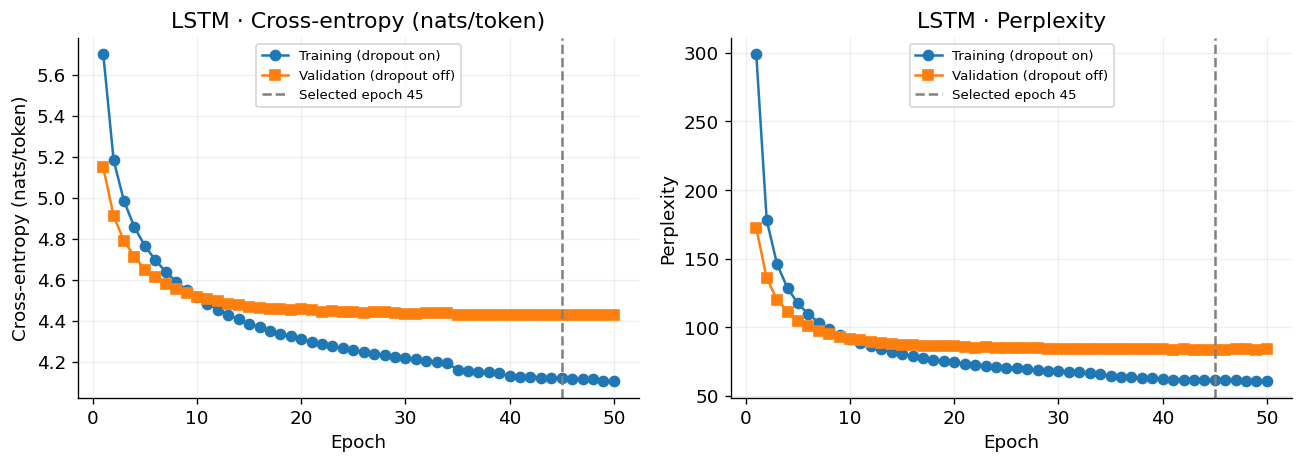

In [11]:
history_df = pd.DataFrame(history)
display(history_df[['epoch','train_ce','val_ce','val_ppl','train_seconds','validation_seconds',
                    'gradient_norm_mean','gradient_clipped_fraction','improved_best']].round(4))
plt.rcParams.update({'font.size':11,'figure.dpi':120,'axes.spines.top':False,'axes.spines.right':False})
fig, axes = plt.subplots(1,2,figsize=(11,4))
for ax,train_col,val_col,label in [(axes[0],'train_ce','val_ce','Cross-entropy (nats/token)'),
                                   (axes[1],'train_ppl','val_ppl','Perplexity')]:
    ax.plot(history_df.epoch,history_df[train_col],marker='o',label='Training (dropout on)')
    ax.plot(history_df.epoch,history_df[val_col],marker='s',label='Validation (dropout off)')
    ax.axvline(best_epoch,color='gray',linestyle='--',label=f'Selected epoch {best_epoch}')
    ax.set(xlabel='Epoch',ylabel=label,title=f'LSTM · {label}'); ax.grid(alpha=0.2); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(RUN_DIR/'learning_curves.png',bbox_inches='tight'); plt.show()

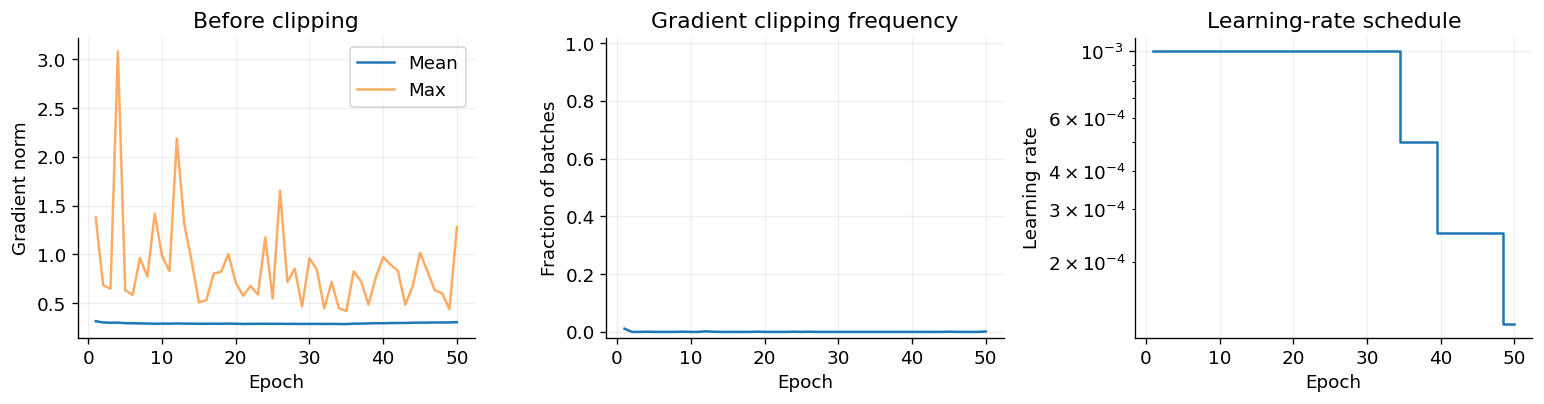

In [12]:
fig,axes=plt.subplots(1,3,figsize=(13,3.5))
axes[0].plot(history_df.epoch,history_df.gradient_norm_mean,label='Mean')
axes[0].plot(history_df.epoch,history_df.gradient_norm_max,label='Max',alpha=.65)
axes[0].set(xlabel='Epoch',ylabel='Gradient norm',title='Before clipping'); axes[0].legend()
axes[1].plot(history_df.epoch,history_df.gradient_clipped_fraction)
axes[1].set(xlabel='Epoch',ylabel='Fraction of batches',title='Gradient clipping frequency',ylim=(-.02,1.02))
axes[2].step(history_df.epoch,history_df.learning_rate,where='mid')
axes[2].set(xlabel='Epoch',ylabel='Learning rate',title='Learning-rate schedule',yscale='log')
for ax in axes: ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(RUN_DIR/'stability.png',bbox_inches='tight'); plt.show()

## 10. Reload and evaluate on test

In [13]:
loaded=torch.load(RUN_DIR/'best.pt',map_location='cpu',weights_only=True)
assert loaded['config']==CFG and loaded['model_source_sha256']==sha256(model_path)
reloaded=LSTMLanguageModel(CFG).to(DEVICE).eval(); reloaded.load_state_dict(loaded['model_state'])
with torch.inference_mode():
    sample_x=torch.from_numpy(arrays['validation'][0][:2]).to(DEVICE)
    torch.testing.assert_close(model(sample_x),reloaded(sample_x),atol=1e-6,rtol=1e-5)
model=reloaded
if VARIANT!='random_trainable':
    assert not model.embedding.weight.requires_grad
    assert tensor_hash(model.embedding.weight)==CFG['embedding_matrix_sha256']
checkpoint_hash=sha256(RUN_DIR/'best.pt')
metrics=None
if EVALUATE:
    test=evaluate_model(model,test_loader,DEVICE)
    test_info=next(d for d in data_checks if d['split']=='test')
    assert test['tokens']==test_info['scored_tokens']
    metrics=dict(run_id=RUN_ID,part='II',variant=VARIANT,seed=CFG['seed'],checkpoint_sha256=checkpoint_hash,
        data_hash=CFG['data_manifest_sha256'],vocab_hash=CFG['vocab_sha256'],data_version=CFG['data_version'],
        test_target_sha256=test_info['target_sha256'],test_nll_sum=test['nll_sum'],test_token_count=test['tokens'],
        test_ce=test['ce'],test_ppl=test['ppl'],test_unknown_target_rate=test_info['unknown_target_rate'],
        best_epoch=best_epoch,best_validation_ce=best_ce,epochs_completed=len(history),epoch_budget=CFG['epochs'],
        stop_reason=selected_result['stop_reason'],total_updates=global_step,
        training_token_exposures=int(history_df.train_tokens.sum()),
        total_parameters=sum(p.numel() for p in model.parameters()),
        trainable_parameters=sum(p.numel() for p in model.parameters() if p.requires_grad),
        weights_bytes=(RUN_DIR/'weights.pt').stat().st_size,weights_mib=(RUN_DIR/'weights.pt').stat().st_size/2**20,
        train_seconds=float(history_df.train_seconds.sum()),validation_seconds=float(history_df.validation_seconds.sum()),
        train_including_validation_seconds=float(history_df.epoch_compute_seconds.sum()),
        own_embedding_training_seconds=embedding_record['embedding_training_seconds'],
        embedding_setup_seconds=embedding_record['setup_seconds'],
        public_pretraining_cost='not measured / external' if VARIANT=='glove_frozen' else 'not applicable',
        baseline_reused=VARIANT=='random_trainable',test_scoring_seconds=test['seconds'],
        evaluation_device=str(DEVICE),evaluation_gpu=ENV['gpu_name'],
        training_devices='; '.join(sorted(set(history_df.training_device))),
        training_gpu_names='; '.join(sorted({str(v) for v in history_df.gpu_name.dropna()})),
        batch_size=CFG['batch_size'],block_length=T,precision=CFG['precision'],
        baseline_selection_sha256=baseline_identity['checkpoint_sha256'])
    atomic_json(SESSION_DIR/'metrics.json',metrics); atomic_json(RUN_DIR/'metrics.json',metrics)
    pd.DataFrame([metrics]).to_csv(RUN_DIR/'lm_metrics.csv',index=False)
    display(pd.DataFrame([metrics])[['variant','test_ce','test_ppl','best_epoch','epochs_completed',
        'total_parameters','trainable_parameters','train_including_validation_seconds','own_embedding_training_seconds']].round(4))
else: print('Test evaluation skipped. Enable EVALUATE for the final report.')

,variant,test_ce,test_ppl,best_epoch,epochs_completed,total_parameters,trainable_parameters,train_including_validation_seconds,own_embedding_training_seconds
0,glove_frozen,4.369,78.9659,45,50,3936592,2936592,1739.8304,0.0


## 11. Matched generation and checkpoint handoff

In [14]:
@torch.inference_mode()
def generate_ids(net, prompt_ids, device, *, max_new_tokens=50, sampling=False,
                 temperature=0.8, top_k=50, seed=123, stop_at_eos=True):
    net.eval()
    context = torch.tensor([[BOS]+list(prompt_ids)],dtype=torch.long,device=device)
    generated = []
    generator = torch.Generator(device=device).manual_seed(seed)
    for _ in range(max_new_tokens):
        logits = net(context[:,-T:])[:,-1,:].clone()
        logits[:,[PAD,BOS,UNK]] = float('-inf')
        if sampling:
            logits = logits/temperature
            values,indices = torch.topk(logits,k=min(top_k,V-3),dim=-1)
            choice = torch.multinomial(values.softmax(-1),1,generator=generator)
            next_id = indices.gather(-1,choice)
        else: next_id = logits.argmax(-1,keepdim=True)
        generated.append(next_id)
        context = torch.cat([context[:,-T:],next_id],dim=1)
        if stop_at_eos and int(next_id.item()) == EOS: break
    return torch.cat(generated,dim=1).squeeze(0) if generated else torch.empty(0,dtype=torch.long,device=device)

# Fresh-instance reload must also reproduce a greedy continuation.
check_model = LSTMLanguageModel(CFG).to(DEVICE).eval(); check_model.load_state_dict(loaded['model_state'])
assert torch.equal(generate_ids(model,prompts[0]['ids'],DEVICE,max_new_tokens=8),
                   generate_ids(check_model,prompts[0]['ids'],DEVICE,max_new_tokens=8))
del check_model

generations = []
if RUN_GENERATION:
    for prompt_id,p in enumerate(prompts):
        for decoding in ['greedy','sample_top50_temperature0.8']:
            ids = generate_ids(model,p['ids'],DEVICE,sampling=decoding!='greedy',seed=CFG['generation_seed']).cpu().tolist()
            record = dict(run_id=RUN_ID,checkpoint_sha256=checkpoint_hash,prompt_id=prompt_id,prompt=p['text'],
                prompt_token_ids=p['ids'],decoding=decoding,temperature=1.0 if decoding=='greedy' else 0.8,
                top_k=None if decoding=='greedy' else 50,seed=CFG['generation_seed'],max_new_tokens=50,
                token_ids=ids,text=' '.join(id_to_token[i] for i in ids),generated_length=len(ids),
                stop_reason='EOS' if ids and ids[-1]==EOS else 'token_limit',
                eos_count=ids.count(EOS),unk_count=ids.count(UNK),device=str(DEVICE))
            generations.append(record)
            print(f'\n{p["text"]} | {decoding}\n{record["text"]}')
    content = ''.join(json.dumps(r,ensure_ascii=False)+'\n' for r in generations)
    (SESSION_DIR/'generation.jsonl').write_text(content,encoding='utf-8')
    (RUN_DIR/'generation.jsonl').write_text(content,encoding='utf-8')


the history of | greedy
the book was written by the book of the book of the book of the book of the book . <EOS>

the history of | sample_top50_temperature0.8
a number of which is the oldest most common american breeds , especially important as the indigenous language . in 1898 , british columbia and the south american association of the united states was the land of the united states , which led to the minnesota territory in 1858 in

the city is | greedy
a major tourist attraction in the city of the city of the city . the city is located in the city of the city of the city of the city of the city . the city is located in the city of the city of the city of the city

the city is | sample_top50_temperature0.8
located in the vicinity of the united states in the past of galveston before the historic campus . the first has shown listed the " galveston bay of the united states " , and the park ' s first season @ - @ length ' s a national register in

during the first | greedy
half of the s

## 12. Common inference workload: CPU and optional GPU

In [15]:
benchmark_rows = []; benchmark_summary = []
workload = dict(prompt_sha256=CFG['prompts_sha256'],prompt_count=len(prompts),new_tokens_per_prompt=50,
    decoding='greedy',suppress_ids=[PAD,BOS,UNK],eos_stopping=False,batch_size=1,
    context_length=T,cache_policy='recompute_prefix_no_state',warmup_repeats=1,timed_repeats=3)
workload_id = object_hash(workload)
atomic_json(RUN_DIR/'benchmark_workload.json',dict(workload,workload_id=workload_id))
if RUN_BENCHMARK:
    benchmark_devices = [torch.device('cpu')]
    if BENCHMARK_GPU and torch.cuda.is_available(): benchmark_devices.append(torch.device('cuda'))
    for bench_device in benchmark_devices:
        bench_model = LSTMLanguageModel(CFG).to(bench_device).eval()
        bench_model.load_state_dict(loaded['model_state'])
        def workload_once():
            for p in prompts:
                output = generate_ids(bench_model,p['ids'],bench_device,stop_at_eos=False,max_new_tokens=50)
                assert output.numel() == 50
        workload_once(); synchronize(bench_device)
        for repeat in range(1,4):
            synchronize(bench_device); start = time.perf_counter()
            workload_once()
            synchronize(bench_device); seconds = time.perf_counter()-start
            benchmark_rows.append(dict(run_id=RUN_ID,checkpoint_sha256=checkpoint_hash,workload_id=workload_id,
                device=str(bench_device),device_name=ENV['cpu'] if bench_device.type=='cpu' else ENV['gpu_name'],
                cpu_threads=torch.get_num_threads(),precision='float32',prompt_count=len(prompts),generated_tokens=len(prompts)*50,
                cache_policy='recompute_prefix_no_state',repeat=repeat,seconds=seconds,
                tokens_per_second=len(prompts)*50/seconds,session_id=SESSION_ID))
        del bench_model
    benchmark_df = pd.DataFrame(benchmark_rows)
    benchmark_df.to_csv(SESSION_DIR/'benchmark.csv',index=False)
    benchmark_df.to_csv(RUN_DIR/'benchmark.csv',index=False)
    for device,group in benchmark_df.groupby('device'):
        benchmark_summary.append(dict(device=device,seconds_median=float(group.seconds.median()),
            seconds_min=float(group.seconds.min()),seconds_max=float(group.seconds.max()),
            tokens_per_second_median=float(group.tokens_per_second.median()),
            tokens_per_second_min=float(group.tokens_per_second.min()),tokens_per_second_max=float(group.tokens_per_second.max())))
    summary_df = pd.DataFrame(benchmark_summary)
    summary_df.to_csv(RUN_DIR/'benchmark_summary.csv',index=False)
    display(summary_df.round(3))
else: print('Inference benchmark skipped. Run it before completing the Part I comparison.')

,device,seconds_median,seconds_min,seconds_max,tokens_per_second_median,tokens_per_second_min,tokens_per_second_max
0,cpu,1.148,1.137,1.189,174.153,168.166,175.942
1,cuda,0.281,0.215,0.292,712.959,685.720,931.321


## 13. Consolidated three-setting comparison

,variant,test_ce,test_ppl,best_validation_ce,best_epoch,train_including_validation_seconds,own_embedding_training_seconds,trainable_parameters
0,random_trainable,4.3535,77.7484,4.4164,47,1751.1850,0.0000,3936592
1,cbow_frozen,4.3602,78.2691,4.4223,36,1455.6069,36.7019,2936592
2,glove_frozen,4.3690,78.9659,4.4283,45,1739.8304,0.0000,2936592


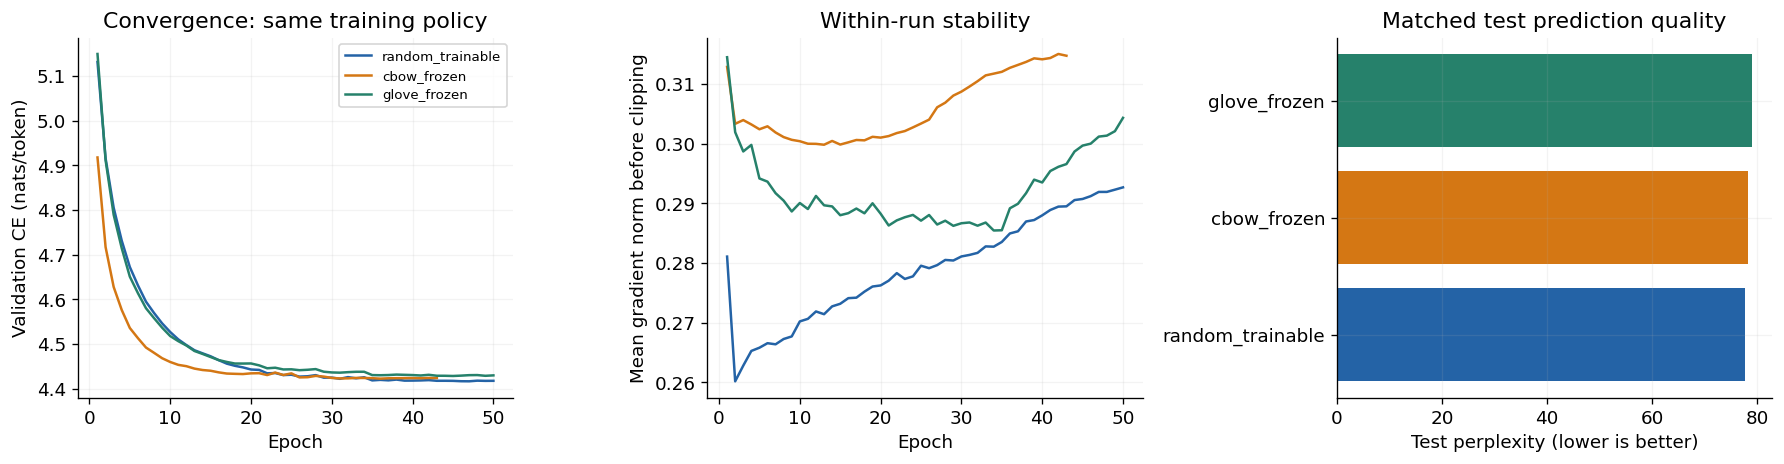

,variant,prompt,decoding,text
0,random_trainable,the history of,greedy,"the goat puzzle is a fictional character , and..."
1,random_trainable,the history of,sample_top50_temperature0.8,a batsman can be lbw in a series of cricket or...
2,random_trainable,the city is,greedy,a grade ii listed building in the city of burn...
3,random_trainable,the city is,sample_top50_temperature0.8,the third of the most popular world war i ( or...
4,random_trainable,during the first,greedy,"half of the season , the first team was held i..."
5,random_trainable,during the first,sample_top50_temperature0.8,"time , the battalion was sent to advance in th..."
6,random_trainable,the team won,greedy,"the first division of the season , and was nam..."
7,random_trainable,the team won,sample_top50_temperature0.8,a record of ten wins and six nations in the wo...
8,cbow_frozen,the history of,greedy,"the goat is a fictional character , and the st..."
9,cbow_frozen,the history of,sample_top50_temperature0.8,"a large object is the only two years , the oth..."


Complete three-setting comparison: True
Rerun this final cell after the other notebooks finish to refresh the comparison.


In [16]:
COMPARISON_DIR=PROJECT_ROOT/'results'/'part_II_lstm'; COMPARISON_DIR.mkdir(parents=True,exist_ok=True)
comparison_runs={
    'random_trainable':'II_lstm_random_reuse_s42_v1',
    'cbow_frozen':'II_lstm_cbow_frozen_s42_v1',
    'glove_frozen':'II_lstm_glove_frozen_s42_v1'}
# If you choose new RUN_IDs, update this mapping in all three notebooks.
comparison_runs[VARIANT]=RUN_ID
rows=[]; histories={}; generation_rows=[]; coverage_rows=[]; benchmark_rows_all=[]
match_keys=['embedding_dim','hidden_size','num_layers','dropout','learning_rate','weight_decay',
    'batch_size','epochs','clip_norm','seed','shuffle_seed','precision','block_length',
    'early_stopping_patience','early_stopping_min_delta','scheduler_factor','scheduler_patience',
    'min_learning_rate','vocab_sha256','data_manifest_sha256','prompts_sha256','baseline']
for variant,rid in comparison_runs.items():
    folder=PROJECT_ROOT/'runs'/rid
    if not (folder/'metrics.json').exists():
        print('Not yet available:',variant); continue
    c=read_json(folder/'config.json'); m=read_json(folder/'metrics.json')
    assert c['embedding_mode']==variant and m['variant']==variant
    for key in match_keys: assert c[key]==CFG[key], f'Unmatched comparison: {variant} / {key}'
    assert m['checkpoint_sha256']==sha256(folder/'best.pt'), 'Stale metrics.'
    assert m['test_target_sha256']==next(d['target_sha256'] for d in data_checks if d['split']=='test')
    rows.append(m); histories[variant]=pd.read_csv(folder/'history.csv')
    if (folder/'generation.jsonl').exists():
        for line in (folder/'generation.jsonl').read_text().splitlines():
            item=json.loads(line); item['variant']=variant; generation_rows.append(item)
    if (folder/'coverage.csv').exists():
        cc=pd.read_csv(folder/'coverage.csv'); cc.insert(0,'variant',variant); coverage_rows.append(cc)
    if (folder/'benchmark.csv').exists():
        bb=pd.read_csv(folder/'benchmark.csv'); bb.insert(0,'variant',variant); benchmark_rows_all.append(bb)
if rows:
    table=pd.DataFrame(rows)
    table.to_csv(COMPARISON_DIR/'embedding_comparison.csv',index=False)
    atomic_json(COMPARISON_DIR/'comparison_status.json',dict(complete=len(rows)==3,
        variants=table.variant.tolist(),updated_utc=datetime.now(timezone.utc).isoformat()))
    display(table[['variant','test_ce','test_ppl','best_validation_ce','best_epoch',
        'train_including_validation_seconds','own_embedding_training_seconds','trainable_parameters']].round(4))
    colors={'random_trainable':'#2463a6','cbow_frozen':'#d47714','glove_frozen':'#26816b'}
    fig,axes=plt.subplots(1,3,figsize=(15,4))
    for variant,h in histories.items():
        axes[0].plot(h.epoch,h.val_ce,label=variant,color=colors[variant])
        axes[1].plot(h.epoch,h.gradient_norm_mean,label=variant,color=colors[variant])
    axes[0].set(xlabel='Epoch',ylabel='Validation CE (nats/token)',title='Convergence: same training policy')
    axes[1].set(xlabel='Epoch',ylabel='Mean gradient norm before clipping',title='Within-run stability')
    axes[2].barh(table.variant,table.test_ppl,color=[colors[v] for v in table.variant])
    axes[2].set(xlabel='Test perplexity (lower is better)',title='Matched test prediction quality')
    axes[0].legend(fontsize=8)
    for ax in axes: ax.grid(alpha=.15)
    fig.tight_layout(); fig.savefig(COMPARISON_DIR/'embedding_comparison.png',bbox_inches='tight'); plt.show()
    if generation_rows:
        generated=pd.DataFrame(generation_rows)
        generated.to_csv(COMPARISON_DIR/'generated_text_comparison.csv',index=False)
        display(generated[['variant','prompt','decoding','text']])
    if coverage_rows: pd.concat(coverage_rows).to_csv(COMPARISON_DIR/'coverage_comparison.csv',index=False)
    if benchmark_rows_all: pd.concat(benchmark_rows_all).to_csv(COMPARISON_DIR/'inference_comparison.csv',index=False)
    print('Complete three-setting comparison:',len(rows)==3)
    print('Rerun this final cell after the other notebooks finish to refresh the comparison.')

## 14. Save handoff and reproducibility files

In [17]:
readme=f"""# DSA4213 Part II: {VARIANT}
This run uses the selected Part I configuration and unchanged prepared data.
Project root: {PROJECT_ROOT}
Baseline study: {BASELINE_STUDY_ID}; selected trial: {selection['selected_trial']}.
Best epoch: {best_epoch}; maximum epochs: {CFG['epochs']}.

## Run / reload
Run 01_data_preparation and complete the tuned Part I LSTM first. Keep their Drive outputs.
Upload the Part II notebook to Colab, select T4 GPU for new LSTM training, check PROJECT_ROOT, Run all.
TRAIN=True, MODE='auto' resumes incomplete LM training from the last completed epoch and reuses completed training.
TRAIN=False performs no fitting; it requires completed artifacts for frozen variants.
Baseline notebook loads Part I weights without fitting. Existing Part I artifacts are not changed.
If CBOW preparation is interrupted before COMPLETE.json, rerunning rebuilds its ten-epoch training from scratch.
Do not manually change saved configs/checksums. Use new run/embedding IDs for deliberate new experiments.

## Reusable inference / Part III encoder
Keep best.pt with lstm_model.py, vocab.json and preprocessing.py.
```python
import torch
from lstm_model import LSTMLanguageModel
package = torch.load('best.pt', map_location='cpu', weights_only=True)
model = LSTMLanguageModel(package['config'])
model.load_state_dict(package['model_state'])
model.eval()
# IDs: use the saved tokenizer/vocabulary, BOS=2, PAD=0; right padding only.
# with torch.inference_mode(): logits = model(input_ids)
# features = model.encode_mean(input_ids) excludes PAD/BOS/EOS; UNK remains.
```
The full frozen embedding table is included in best.pt, so inference needs no public-vector download.

## Outputs and measurement definitions
config.json: immutable settings and baseline/embedding hashes.
best.pt: selected inference package. weights.pt: pure state dict. last.pt: frozen-run recovery checkpoint.
history.csv, learning_curves.png, stability.png: training, validation, learning-rate and gradient evidence.
initialization_audit.json: same non-embedding initialization; frozen table unchanged.
lm_metrics.csv: token-weighted test CE in nats and exp(CE), with PAD excluded and EOS/UNK scored.
generation.jsonl: same saved prompts and decoding as Part I (greedy and temperature .8/top-50; at most 50 tokens).
benchmark*.csv: same fixed CPU/GPU workload; compare only compatible device rows.
coverage*.csv: fixed-vector coverage; ordinary vocabulary excludes special IDs.
embedding_record.json: separate own-embedding training cost; public pretraining cost is external/unmeasured.
sessions/: hardware, versions, checkpoint timing, and per-execution evidence.
results/part_II_lstm/: automatically consolidated results when all three notebooks have run.
LM training time includes validation; setup/download and checkpoint I/O are separate.
Baseline cost is the original selected trial cost; its seven-trial search is recorded separately in baseline provenance.

## Interpretation
Single seed; gradient curves characterize this run, not seed-to-seed robustness.
Configuration was selected using the random baseline. It may favor that setting.
CBOW versus GloVe also changes training objective, corpus size/domain and vector scale.
Random-trained versus frozen changes both initialization and trainability; do not attribute all effects to pretraining.
Public embeddings may have corpus overlap that cannot be audited from released vectors.
Validation selects LM epochs; test is for final reporting, never tuning.

## Attribution
User's tuned Part I notebook and data-preparation notebook supply the architecture and data contract.
Assignment1_2026 specifies the comparison. Substantial coding assistance: ChatGPT.
Gensim Word2Vec: https://radimrehurek.com/gensim/models/word2vec.html
GloVe (Pennington et al., 2014): https://nlp.stanford.edu/projects/glove/
Gensim-data packaging: https://github.com/piskvorky/gensim-data
PyTorch: https://docs.pytorch.org/docs/stable/index.html
Write your own report interpretation from the measured outputs.
"""
(RUN_DIR/'README.md').write_text(readme,encoding='utf-8')
files={str(p.relative_to(RUN_DIR)):dict(bytes=p.stat().st_size,sha256=sha256(p))
       for p in sorted(RUN_DIR.rglob('*')) if p.is_file() and p.name!='artifact_manifest.json' and not p.name.endswith('.tmp')}
atomic_json(RUN_DIR/'artifact_manifest.json',dict(variant=VARIANT,run_id=RUN_ID,files=files))
print('Saved:',RUN_DIR)
print('Next time: TRAIN=False to load without fitting; keep the same IDs.')

Saved: /content/drive/MyDrive/DSA4213_Assignment1/runs/II_lstm_glove_frozen_s42_v1
Next time: TRAIN=False to load without fitting; keep the same IDs.
